# Human Gaze Dynamics in Natural Scenes (COCO-FreeView)

**Question:** How does human free-viewing behaviour unfold over time, and how much of it is shared between people vs. driven by the specific image?

1. Fixation durations and saccade amplitudes (basic oculomotor statistics)
2. How gaze moves away from the centre over successive fixations
3. Individual differences between the 10 observers
4. Inter-observer consistency: is gaze image-specific, or just a generic centre bias?

**Data:** `COCOFreeView_fixations_trainval.json` (train + validation splits; the test split is withheld) from COCO-FreeView: Chen, Y., Yang, Z., Chakraborty, S., Mondal, S., Ahn, S., Samaras, D., Hoai, M., & Zelinsky, G. (2022). *Characterizing Target-Absent Human Attention.* CVPRW, 5031-5040. 10 students free-viewed COCO-Search18 images for 5 s each. Images were resized to 1680x1050 with zero padding (aspect ratio kept). Place the JSON next to this notebook.

In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "axes.titleweight": "bold"})
BLUE, TEAL, ORANGE, GREY = "#2b5c8f", "#1b9e77", "#d95f02", "#888888"
RNG = np.random.default_rng(0)

SCREEN_W, SCREEN_H = 1680, 1050            # stimulus / screen size in pixels
CX, CY = SCREEN_W / 2, SCREEN_H / 2        # screen centre (840, 525)

with open("COCOFreeView_fixations_trainval.json") as f:
    trials = json.load(f)
print(f"{len(trials):,} trials loaded")     # do NOT print the data itself

43,048 trials loaded


## 1. Flatten to one row per fixation + sanity checks

In [2]:
rows = []
for tid, t in enumerate(trials):
    x, y, d = np.asarray(t["X"]), np.asarray(t["Y"]), np.asarray(t["T"])
    sac = np.r_[np.nan, np.hypot(np.diff(x), np.diff(y))]   # amplitude of the saccade INTO each fixation
    for k in range(len(x)):
        rows.append((tid, t["name"], t["subject"], k + 1, x[k], y[k], d[k], sac[k]))
fx = pd.DataFrame(rows, columns=["trial", "image", "subject", "order", "x", "y", "dur", "sacc_px"])
fx["dist_center"] = np.hypot(fx.x - CX, fx.y - CY)

assert fx[["x", "y", "dur"]].notna().all().all()
assert fx.x.between(0, SCREEN_W).all() and fx.y.between(0, SCREEN_H).all()
print(f"{len(fx):,} fixations | {fx.subject.nunique()} subjects | {fx.image.nunique():,} images | "
      f"{fx.groupby('trial').size().mean():.1f} fixations/trial")
print("conditions:", {t['condition'] for t in trials})

665,005 fixations | 10 subjects | 4,317 images | 15.4 fixations/trial
conditions: {'freeview'}


### Why fixation 1 is treated separately
The dataset readme states that `X`, `Y` and `T` include **the initial center fixation**, so fixation 1 is the forced start position, not a viewer's choice. The check below confirms it: fixation 1 is tightly clustered around the centre. I therefore report fixation 1 separately and exclude it from "centre bias" claims.

In [3]:
f1 = fx[fx.order == 1]
print(f"Fixation 1: mean = ({f1.x.mean():.0f}, {f1.y.mean():.0f}), SD = ({f1.x.std():.0f}, {f1.y.std():.0f}) px")
print(f"Fixation 2+: SD = ({fx[fx.order>1].x.std():.0f}, {fx[fx.order>1].y.std():.0f}) px")
print(f"Median duration  fixation 1: {f1.dur.median():.0f} ms   later fixations: {fx[fx.order>1].dur.median():.0f} ms")

Fixation 1: mean = (838, 520), SD = (36, 30) px
Fixation 2+: SD = (306, 188) px
Median duration  fixation 1: 248 ms   later fixations: 230 ms


## 2. Fixation durations and saccade amplitudes
Saccade amplitude = Euclidean distance between consecutive fixations, `sqrt(dx**2 + dy**2)` (computed with `np.hypot`).

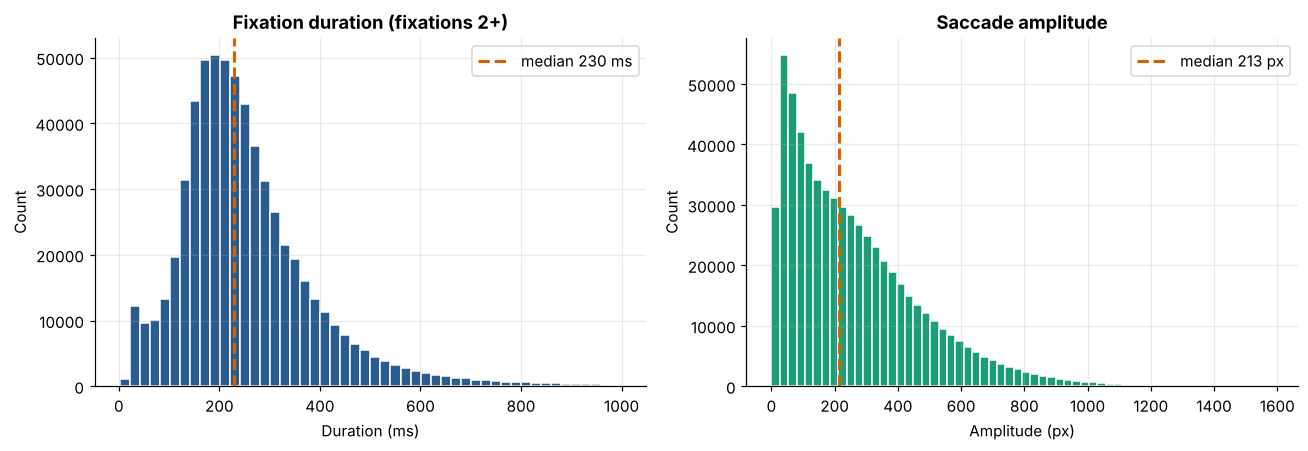

Duration  ms [5,25,50,75,95]%: [78.0, 168.0, 230.0, 315.0, 524.0] | mean 262 +/- SD 177
Saccade   px [5,25,50,75,95]%: [27.0, 93.0, 213.0, 374.0, 675.0] | mean 262 +/- SD 210
Fixations dropped for duration >1000 ms in the plot only: 3,986 (0.64%)


In [4]:
later = fx[fx.order > 1]
dur, sac = later.dur, later.sacc_px

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].hist(dur[dur < 1000], bins=50, color=BLUE, edgecolor="white")
ax[0].axvline(dur.median(), color=ORANGE, ls="--", lw=2, label=f"median {dur.median():.0f} ms")
ax[0].set(title="Fixation duration (fixations 2+)", xlabel="Duration (ms)", ylabel="Count"); ax[0].legend()

ax[1].hist(sac, bins=60, color=TEAL, edgecolor="white")
ax[1].axvline(sac.median(), color=ORANGE, ls="--", lw=2, label=f"median {sac.median():.0f} px")
ax[1].set(title="Saccade amplitude", xlabel="Amplitude (px)", ylabel="Count"); ax[1].legend()
plt.tight_layout(); plt.savefig("figure1_fixation_saccade_stats.png", dpi=200); plt.show()

q = lambda s: s.quantile([.05, .25, .5, .75, .95]).round(0).tolist()
print("Duration  ms [5,25,50,75,95]%:", q(dur), f"| mean {dur.mean():.0f} +/- SD {dur.std():.0f}")
print("Saccade   px [5,25,50,75,95]%:", q(sac), f"| mean {sac.mean():.0f} +/- SD {sac.std():.0f}")
print(f"Fixations dropped for duration >1000 ms in the plot only: {(dur >= 1000).sum():,} ({(dur>=1000).mean():.2%})")

## 3. Does gaze spread outward over time?
Mean distance from screen centre per fixation index, with a **95% CI from a bootstrap over images** (resampling images, not fixations, because fixations from the same image/trial are not independent). The grey point is fixation 1 - the experimental start position.

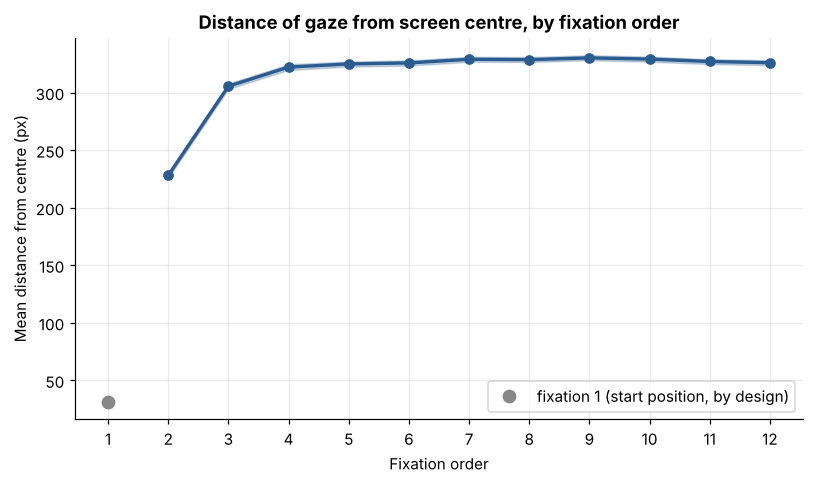

 order  mean_px  ci_low  ci_high
     1     31.3    30.9     31.6
     2    228.1   226.0    230.2
     3    305.6   303.3    307.9
     4    322.2   319.7    324.6
     5    324.9   322.6    327.0
     6    325.8   323.5    328.0
     7    329.0   326.8    331.0
     8    328.6   326.6    330.9
     9    330.2   328.1    332.4
    10    329.1   326.9    331.2
    11    327.0   324.8    329.0
    12    326.0   323.8    328.1


In [5]:
MAXK = 12
imgs = fx.image.unique()
by_img = {k: fx[fx.order == k].groupby("image").dist_center.agg(["sum", "count"]) for k in range(1, MAXK + 1)}

means, lo, hi = [], [], []
for k in range(1, MAXK + 1):
    s = by_img[k].reindex(imgs).fillna(0)
    sums, cnts = s["sum"].values, s["count"].values
    means.append(sums.sum() / cnts.sum())
    boots = []
    for _ in range(500):
        idx = RNG.integers(0, len(imgs), len(imgs))
        boots.append(sums[idx].sum() / cnts[idx].sum())
    lo.append(np.percentile(boots, 2.5)); hi.append(np.percentile(boots, 97.5))
means, lo, hi = map(np.array, (means, lo, hi))
ks = np.arange(1, MAXK + 1)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.fill_between(ks[1:], lo[1:], hi[1:], color=BLUE, alpha=.25)
ax.plot(ks[1:], means[1:], "-o", color=BLUE, lw=2.2)
ax.plot(ks[:1], means[:1], "o", color=GREY, ms=8, label="fixation 1 (start position, by design)")
ax.set(title="Distance of gaze from screen centre, by fixation order", xlabel="Fixation order",
       ylabel="Mean distance from centre (px)", xticks=ks); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figure2_center_distance_by_order.png", dpi=200); plt.show()
print(pd.DataFrame({"order": ks, "mean_px": means.round(1), "ci_low": lo.round(1), "ci_high": hi.round(1)}).to_string(index=False))

## 4. Where do people look, and how similar are individual scanpaths?
Left: fixation density (fixations 2+, so the forced start position doesn't dominate), log colour scale. Right: three observers on the same image; stars mark each observer's first fixation.

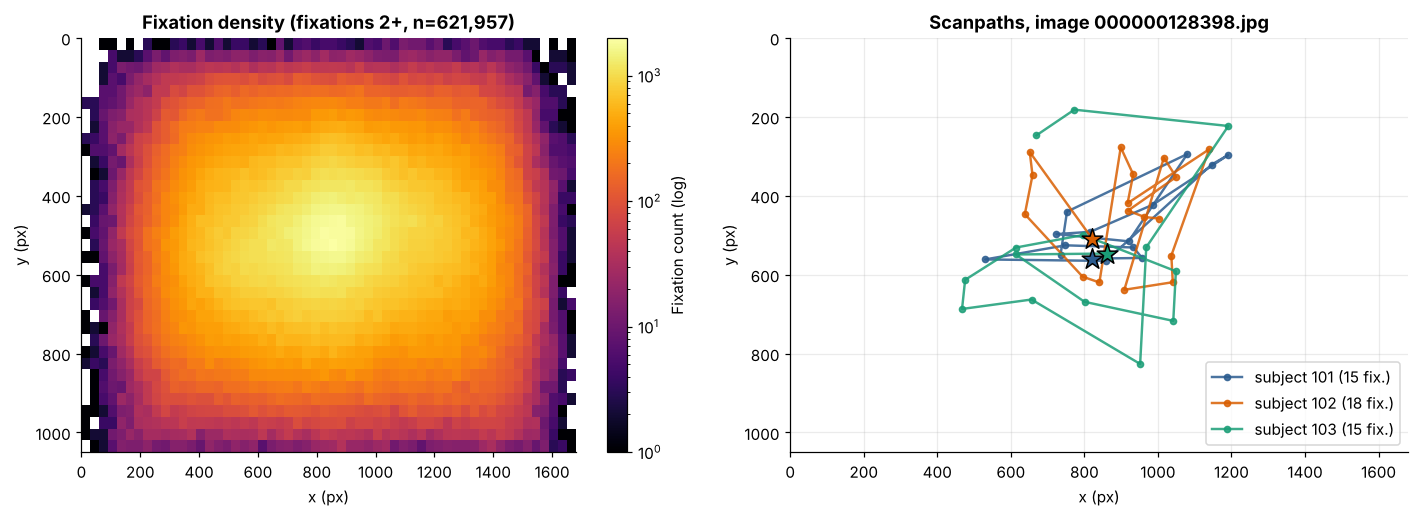

In [6]:
from matplotlib.colors import LogNorm
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
h = a1.hist2d(later.x, later.y, bins=[56, 35], range=[[0, SCREEN_W], [0, SCREEN_H]], cmap="inferno", norm=LogNorm())
plt.colorbar(h[3], ax=a1, label="Fixation count (log)")
a1.invert_yaxis(); a1.grid(False)
a1.set(title=f"Fixation density (fixations 2+, n={len(later):,})", xlabel="x (px)", ylabel="y (px)")

ex_img = trials[0]["name"]
for c, t in zip([BLUE, ORANGE, TEAL], [t for t in trials if t["name"] == ex_img][:3]):
    a2.plot(t["X"], t["Y"], "-o", color=c, lw=1.6, ms=4, alpha=.85, label=f"subject {t['subject']} ({t['length']} fix.)")
    a2.scatter(t["X"][0], t["Y"][0], marker="*", s=200, color=c, edgecolor="k", zorder=5)
a2.set(xlim=(0, SCREEN_W), ylim=(SCREEN_H, 0), title=f"Scanpaths, image {ex_img}", xlabel="x (px)", ylabel="y (px)")
a2.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figure3_density_and_scanpaths.png", dpi=200); plt.show()

## 5. Individual differences between the 10 observers

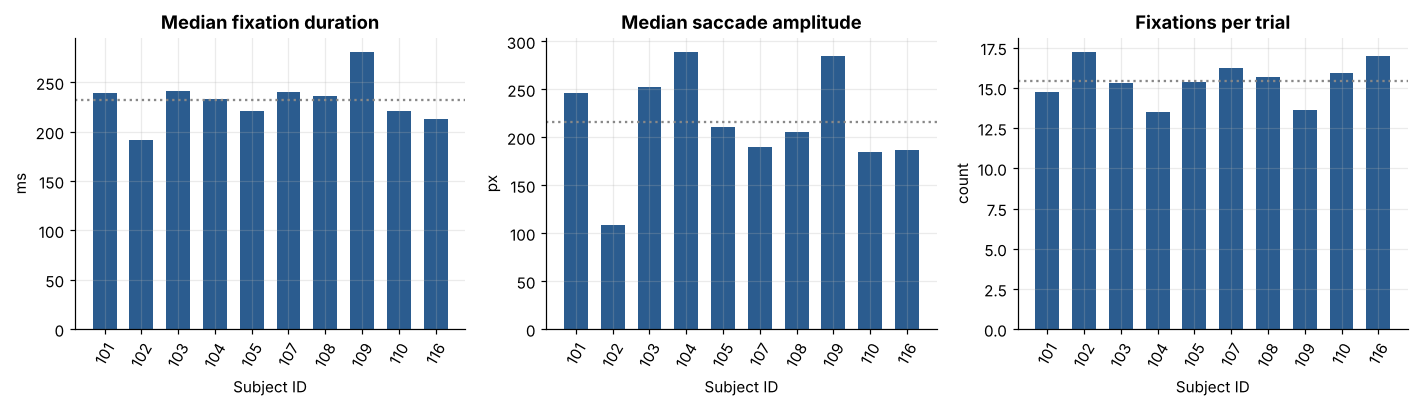

         dur_med  sac_med      n  fix_per_trial
subject                                        
101        239.0    246.3  59252           14.7
102        192.0    108.6  70108           17.2
103        241.0    252.6  61678           15.3
104        233.0    289.2  53979           13.5
105        221.0    210.5  61987           15.4
107        240.0    189.6  65658           16.2
108        236.0    205.5  61821           15.6
109        281.0    285.0  54381           13.6
110        221.0    185.1  64079           15.9
116        213.0    187.1  69014           17.0


In [7]:
per = later.groupby("subject").agg(dur_med=("dur", "median"), sac_med=("sacc_px", "median"), n=("dur", "size"))
per["fix_per_trial"] = fx.groupby(["subject", "trial"]).size().groupby("subject").mean()

fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, col, ttl, unit in zip(ax, ["dur_med", "sac_med", "fix_per_trial"],
        ["Median fixation duration", "Median saccade amplitude", "Fixations per trial"], ["ms", "px", "count"]):
    a.bar(per.index.astype(str), per[col], color=BLUE, width=.65)
    a.axhline(per[col].mean(), color=GREY, ls=":", lw=1.5)
    a.set(title=ttl, xlabel="Subject ID", ylabel=unit)
    a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.savefig("figure4_individual_differences.png", dpi=200); plt.show()
print(per.round(1).to_string())

## 6. Is gaze image-specific, or just a centre bias?
Most images were viewed by every observer, so I can measure **inter-observer consistency** and compare it against a baseline that has no image information at all.

**(a) Saliency-map agreement.** For each image and each observer, I build a smoothed fixation map (fixations 2+, Gaussian blur) and correlate it (Pearson CC) with
- the map of the *other* observers on the **same image** (leave-one-out), and
- the map of observers on a **different, randomly chosen image** (this captures pure centre bias / generic spatial prior).

If gaze were only centre bias, the two correlations would be equal.

**(b) Scanpath agreement (DTW).** Dynamic time warping distance between two observers' fixation sequences on the same image, compared with pairs taken from different images (500 sampled images).

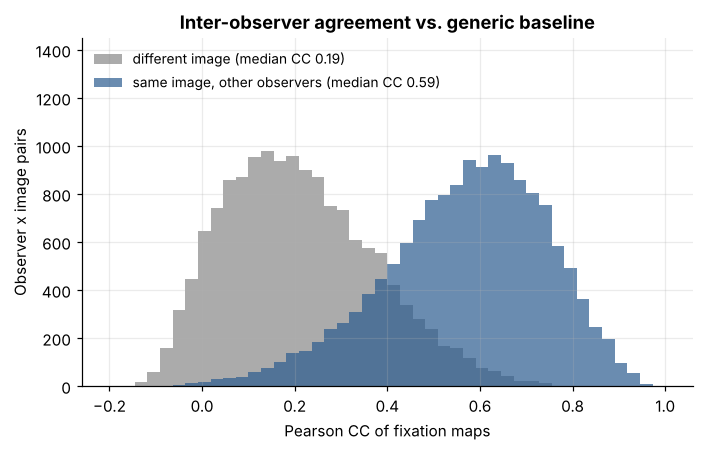

n = 14,920 pairs | same-image CC 0.586 vs different-image CC 0.195 | same > different in 94.0% of pairs


In [8]:
GW, GH, DS, SIGMA = SCREEN_W // 24, SCREEN_H // 24, 24, 2.0     # 70 x 43 grid, ~1.5 deg-ish blur (sigma = 2 cells)

def fixmap(xs, ys):
    m = np.zeros((GH, GW))
    gx = np.clip((np.asarray(xs) / DS).astype(int), 0, GW - 1); gy = np.clip((np.asarray(ys) / DS).astype(int), 0, GH - 1)
    np.add.at(m, (gy, gx), 1)
    return gaussian_filter(m, SIGMA).ravel()

cc = lambda a, b: np.corrcoef(a, b)[0, 1]

by_image = {}
for t in trials:
    by_image.setdefault(t["name"], []).append(t)
multi = [n for n, v in by_image.items() if len(v) >= 5]
sample = list(RNG.choice(multi, 1500, replace=False))

same, diff = [], []
for name in sample:
    ts = by_image[name]
    other_img = RNG.choice([n for n in sample if n != name])
    ot = by_image[other_img]
    other_map = fixmap(np.concatenate([t["X"][1:] for t in ot]), np.concatenate([t["Y"][1:] for t in ot]))
    for i, t in enumerate(ts):
        if len(t["X"]) < 3: continue
        mine = fixmap(t["X"][1:], t["Y"][1:])
        rest = [u for j, u in enumerate(ts) if j != i]
        loo = fixmap(np.concatenate([u["X"][1:] for u in rest]), np.concatenate([u["Y"][1:] for u in rest]))
        same.append(cc(mine, loo)); diff.append(cc(mine, other_map))
same, diff = np.array(same), np.array(diff)

fig, ax = plt.subplots(figsize=(6.5, 4.2))
bins = np.linspace(-.2, 1, 45)
ax.hist(diff, bins, color=GREY, alpha=.7, label=f"different image (median CC {np.median(diff):.2f})")
ax.hist(same, bins, color=BLUE, alpha=.7, label=f"same image, other observers (median CC {np.median(same):.2f})")
ax.set(title="Inter-observer agreement vs. generic baseline", xlabel="Pearson CC of fixation maps", ylabel="Observer x image pairs", ylim=(0, 1450)); ax.legend(loc="upper left", fontsize=9, frameon=False)
plt.tight_layout(); plt.savefig("figure5_consistency.png", dpi=200); plt.show()
print(f"n = {len(same):,} pairs | same-image CC {np.median(same):.3f} vs different-image CC {np.median(diff):.3f} "
      f"| same > different in {(same > diff).mean():.1%} of pairs")

DTW distance (px, lower = more similar): same image 159 vs different image 186  (n=500 pairs)


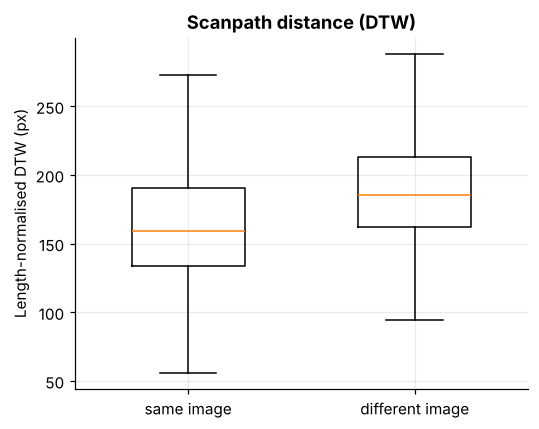

In [9]:
def dtw(a, b):
    n, m = len(a), len(b)
    D = np.full((n + 1, m + 1), np.inf); D[0, 0] = 0
    cost = np.hypot(a[:, None, 0] - b[None, :, 0], a[:, None, 1] - b[None, :, 1])
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            D[i, j] = cost[i-1, j-1] + min(D[i-1, j], D[i, j-1], D[i-1, j-1])
    return D[n, m] / (n + m)                      # length-normalised, in px

path = lambda t: np.c_[t["X"][1:], t["Y"][1:]]
dsame, ddiff = [], []
dtw_imgs = sample[:500]
for name in dtw_imgs:
    ts = [t for t in by_image[name] if len(t["X"]) > 3]
    if len(ts) < 2: continue
    pick = RNG.choice(len(ts), 2, replace=False)
    dsame.append(dtw(path(ts[pick[0]]), path(ts[pick[1]])))
    other = by_image[RNG.choice([n for n in dtw_imgs if n != name])]
    other = [t for t in other if len(t["X"]) > 3]
    if other: ddiff.append(dtw(path(ts[pick[0]]), path(other[RNG.integers(len(other))])))

print(f"DTW distance (px, lower = more similar): same image {np.median(dsame):.0f} vs different image {np.median(ddiff):.0f}  (n={len(dsame)} pairs)")
fig, ax = plt.subplots(figsize=(5, 4))
ax.boxplot([dsame, ddiff], tick_labels=["same image", "different image"], showfliers=False, widths=.5)
ax.set(title="Scanpath distance (DTW)", ylabel="Length-normalised DTW (px)")
plt.tight_layout(); plt.savefig("figure6_dtw.png", dpi=200); plt.show()

## Limitations
- Coordinates are in pixels on the 1680x1050 padded canvas; the readme gives no viewing distance, so degrees of visual angle are not computed. Padded (black) borders mean the canvas centre equals the image centre, but fixation density near the left/right edges is naturally low for images that do not fill the canvas.
- This file holds only the train + valid splits (665,005 of the 822,602 fixations in the full release).
- 10 observers only, so individual-difference results are descriptive.
- Smoothed-map correlation is a coarse similarity measure; established scanpath metrics (MultiMatch, ScanMatch) and saliency metrics (AUC, NSS) would be the next step.
- The analysis is purely descriptive: it does not yet relate gaze to image content (objects, saliency models, captions).

## Next step
Relate fixation location and timing to image content (e.g. COCO object annotations: do people fixate objects earlier/longer?), or compare observed scanpaths with a saliency-model baseline.